In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

assets = pd.read_csv("assets_universe.csv")
prices = pd.read_csv("prices_daily.csv")

print("Assets:", assets.shape)
print("Prices:", prices.shape)

display(assets.head())
display(prices.head())

Assets: (31, 7)
Prices: (40049, 9)


,asset_id,ticker,name,asset_class,market,currency,sector
0,A01,RY.TO,Royal Bank of Canada,equity,TSX,CAD,Financials
1,A02,TD.TO,Toronto-Dominion Bank,equity,TSX,CAD,Financials
2,A03,MFC.TO,Manulife Financial,equity,TSX,CAD,Financials
3,A04,ENB.TO,Enbridge,equity,TSX,CAD,Energy
4,A05,CNQ.TO,Canadian Natural Resources,equity,TSX,CAD,Energy


,date,ticker,open,high,low,close,adj_close,volume,currency
0,2021-11-12,AAPL,148.429993,150.399994,147.479996,149.990005,146.398193,63804000,USD
1,2021-11-15,AAPL,150.369995,151.880005,149.429993,150.000000,146.407913,59222800,USD
2,2021-11-16,AAPL,149.940002,151.490005,149.339996,151.000000,147.384018,59256200,USD
3,2021-11-17,AAPL,151.000000,155.000000,150.990005,153.490005,149.814392,88807000,USD
4,2021-11-18,AAPL,153.710007,158.669998,153.050003,157.869995,154.089508,137827700,USD


In [19]:
## Check missing values and duplicates
print(prices.isna().sum())

print(
    "Duplicate date-ticker rows:",
    prices.duplicated(subset=["date", "ticker"]).sum()
)

print("Number of assets:", prices["ticker"].nunique())

print("Earliest date:", prices["date"].min())
print("Latest date:", prices["date"].max())

date         0
ticker       0
open         0
high         0
low          0
close        0
adj_close    0
volume       0
currency     0
dtype: int64
Duplicate date-ticker rows: 0
Number of assets: 31
Earliest date: 2021-11-12
Latest date: 2026-11-12


,date,ticker,open,high,low,close,adj_close,volume,currency
1255,2021-11-12,AGG,114.500000,114.589996,114.260002,114.320000,96.721313,4554700,USD
1256,2021-11-15,AGG,114.300003,114.309998,113.900002,113.900002,96.365997,6405000,USD
1257,2021-11-16,AGG,113.919998,114.110001,113.839996,113.860001,96.332153,7484000,USD
1258,2021-11-17,AGG,113.790001,114.129997,113.769997,114.129997,96.560570,7173100,USD
1259,2021-11-18,AGG,114.050003,114.279999,114.029999,114.230003,96.645164,4226900,USD


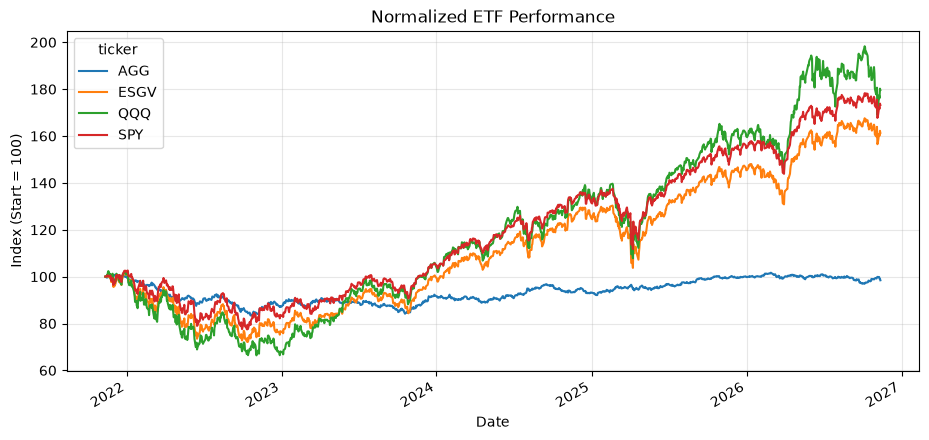

In [20]:
## focus on four ETFs: SPY, QQQ, ESGV, AGG
## EGSV: the fund selected based on ESG critieria
tickers = ["ESGV", "SPY", "AGG", "QQQ"]

df = prices[prices["ticker"].isin(tickers)].copy()

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["ticker", "date"])

display(df.head())

## historical prices of the four ETFs
wide = df.pivot(
    index="date",
    columns="ticker",
    values="adj_close"
)

wide = wide.dropna()

normalized = wide / wide.iloc[0] * 100

normalized.plot(figsize=(11, 5))

plt.title("Normalized ETF Performance")
plt.xlabel("Date")
plt.ylabel("Index (Start = 100)")
plt.grid(alpha=0.3)
plt.show()

In [21]:
## financial risk metrics: volatility, retrun, drawdown

# Calculate daily returns
returns = wide.pct_change().dropna()

# Calculate annualized historical returns
years = (wide.index[-1] - wide.index[0]).days / 365.25

annual_return = (wide.iloc[-1] / wide.iloc[0]) ** (1 / years) - 1

# Calculate annualized volatility
# Assuming approximately 252 trading days per year
annual_volatility = returns.std() * np.sqrt(252)

# Calculate maximum drawdown
# Measures the largest decline from a previous peak
drawdown = wide / wide.cummax() - 1
max_drawdown = drawdown.min()

# Summarize the risk and return metrics
summary = pd.DataFrame({
    "Annualized Return": annual_return,
    "Annualized Volatility": annual_volatility,
    "Maximum Drawdown": max_drawdown
})

display(summary.style.format("{:.2%}"))

,Annualized Return,Annualized Volatility,Maximum Drawdown
ticker,,,
AGG,-0.31%,6.16%,-17.24%
ESGV,10.04%,18.72%,-28.81%
QQQ,12.43%,23.36%,-35.12%
SPY,11.62%,17.33%,-24.50%


In [22]:
## Calculate correlations between daily ETF returns
correlation = returns.corr()

display(correlation.round(2))

ticker,AGG,ESGV,QQQ,SPY
ticker,,,,
AGG,1.00,0.23,0.19,0.22
ESGV,0.23,1.00,0.96,0.99
QQQ,0.19,0.96,1.00,0.95
SPY,0.22,0.99,0.95,1.00


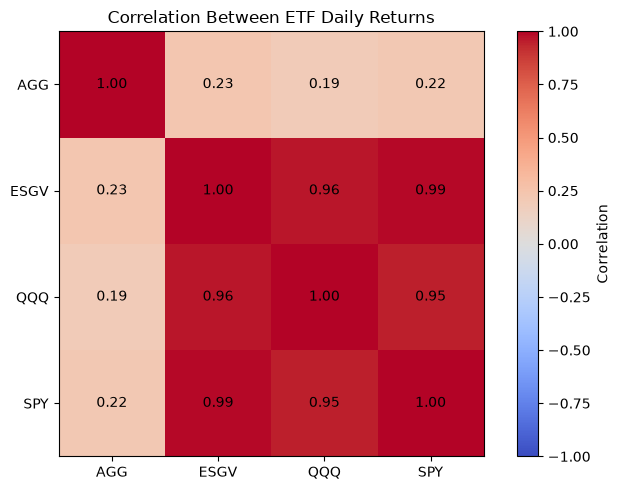

In [23]:

# Visualize the correlation matrix
fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.index)))

ax.set_xticklabels(correlation.columns)
ax.set_yticklabels(correlation.index)

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        ax.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, ax=ax, label="Correlation")
plt.title("Correlation Between ETF Daily Returns")
plt.tight_layout()
plt.show()


### Correlation Analysis

We calculated the correlation between daily returns of four ETFs: ESGV, SPY, QQQ, and AGG.

ESGV and SPY had a correlation of 0.99, while ESGV and QQQ had a correlation of 0.96. This suggests that these equity ETFs moved very similarly during the period and may offer limited additional diversification when combined.

In contrast, ESGV and AGG had a much lower correlation of 0.23. Since AGG provides bond exposure, combining it with ESGV may help reduce overall portfolio volatility.

Based on these findings, we will compare three hypothetical portfolios with different ESGV and AGG allocations to examine the trade-off between historical return and risk.

This analysis is especially relevant to Mateo, whose investment goals include balancing growth and stability while considering ESG preferences.